# LoTiC on Rotating 2-Moons

This notebook trains LoTiC from official pretrained backbones, evaluates every unseen
future domain, and saves the checkpoints and records produced by the run.

## Configuration

In [1]:
from pathlib import Path
import json, os, pickle, platform, random, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import display
from transformers import AutoModel
from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "moons.pkl"
CHECKPOINT_DIR = ROOT / "checkpoints"
RECORD_DIR = ROOT / "records"
CHECKPOINT_DIR.mkdir(exist_ok=True)
RECORD_DIR.mkdir(exist_ok=True)

requested = os.environ.get("LOTIC_BACKBONES", "distilbert,qwen3,llama3")
BACKBONES = [name.strip() for name in requested.split(",") if name.strip()]
SEED = 43
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_TRAIN, N_TEST, NUM_CLASSES = 15, 5, 2
RANK = 8
PCT_START, WD, CLIP, PRINT_EVERY = 0.3, 1e-4, 1.0, 10

CFG = {
    "distilbert": {
        "model": "distilbert-base-uncased",
        "name": "DistilBERT",
        "size": "66M",
        "epochs": 200,
        "lr": 1e-3,
        "alpha": 64.0,
        "dtype": torch.float32,
        "targets": ("q_lin", "k_lin", "v_lin"),
        "pool": "first",
        "file": "distilbert",
    },
    "qwen3": {
        "model": "Qwen/Qwen3-0.6B",
        "name": "Qwen3-0.6B",
        "size": "0.6B",
        "epochs": 500,
        "lr": 1e-3,
        "alpha": 64.0,
        "dtype": torch.float32,
        "targets": ("q_proj", "k_proj", "v_proj"),
        "pool": "last",
        "file": "qwen3_0_6b",
    },
    "llama3": {
        "model": "meta-llama/Meta-Llama-3-8B",
        "name": "LLaMA-3-8B",
        "size": "8B",
        "epochs": 500,
        "lr": 1e-3,
        "alpha": 128.0,
        "dtype": torch.bfloat16,
        "targets": ("q_proj", "k_proj", "v_proj"),
        "pool": "last",
        "file": "llama3_8b",
    },
}
unknown = sorted(set(BACKBONES) - set(CFG))
if unknown:
    raise ValueError(f"Unknown backbone(s): {unknown}")

def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"device={DEVICE} | backbones={', '.join(CFG[name]['name'] for name in BACKBONES)}")

device=cuda | backbones=DistilBERT, Qwen3-0.6B, LLaMA-3-8B


## Data

In [2]:
with open(DATA_PATH, "rb") as handle:
    domains = pickle.load(handle)["datasets"]

observed = [
    (t, torch.as_tensor(domains[t][0], dtype=torch.float32), torch.as_tensor(domains[t][1], dtype=torch.long))
    for t in range(N_TRAIN)
]
future = [
    (t, torch.as_tensor(domains[t][0], dtype=torch.float32), torch.as_tensor(domains[t][1], dtype=torch.long))
    for t in range(N_TRAIN, N_TRAIN + N_TEST)
]
all_points = torch.cat([x for _, x, _ in observed + future])
x_margin = 0.35
x_limits = (float(all_points[:, 0].min()) - x_margin, float(all_points[:, 0].max()) + x_margin)
y_limits = (float(all_points[:, 1].min()) - x_margin, float(all_points[:, 1].max()) + x_margin)
grid_x, grid_y = np.meshgrid(
    np.linspace(*x_limits, 100), np.linspace(*y_limits, 100)
)
decision_grid = torch.tensor(
    np.column_stack([grid_x.ravel(), grid_y.ravel()]), dtype=torch.float32
)
print(f"{len(observed)} observed domains | {len(future)} future domains | {len(observed[0][1])} points per domain")

15 observed domains | 5 future domains | 200 points per domain


## LoTiC

In [3]:
class FlowCoreLayer(nn.Module):
    def __init__(self, original_layer, rank, alpha):
        super().__init__()
        self.original_layer = original_layer
        self.rank = rank
        self.scaling = alpha / rank
        self.down_proj = nn.Parameter(torch.randn(original_layer.in_features, rank) * 0.01)
        self.up_proj = nn.Parameter(torch.zeros(rank, original_layer.out_features))
        self.generator = nn.Parameter(torch.zeros(rank, rank))
        self.current_t = 0.0

    def set_time(self, t):
        self.current_t = float(t)

    def temporal_core(self, device, dtype):
        t = torch.tensor(self.current_t, device=device, dtype=torch.float32)
        return torch.linalg.matrix_exp(t * self.generator.float()).to(device=device, dtype=dtype)

    def forward(self, x):
        base = self.original_layer(x)
        update = (x.float() @ self.down_proj) @ self.temporal_core(x.device, torch.float32)
        return base + ((update @ self.up_proj) * self.scaling).to(base.dtype)


def parent_module(model, name):
    parts = name.split(".")
    parent = model
    for part in parts[:-1]:
        parent = getattr(parent, part)
    return parent, parts[-1]


def apply_lotic(model, suffixes, alpha):
    names = [
        name for name, module in model.named_modules()
        if isinstance(module, nn.Linear) and any(name.endswith(suffix) for suffix in suffixes)
    ]
    for name in names:
        parent, attribute = parent_module(model, name)
        setattr(parent, attribute, FlowCoreLayer(getattr(parent, attribute), RANK, alpha))
    return names


class LoTiC(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        config = CFG[backbone]
        source = os.environ.get("LOTIC_LLAMA_MODEL", config["model"]) if backbone == "llama3" else config["model"]
        self.pool = config["pool"]
        self.featurizer = AutoModel.from_pretrained(source, dtype=config["dtype"])
        for parameter in self.featurizer.parameters():
            parameter.requires_grad = False
        hidden = self.featurizer.config.hidden_size
        self.coord_proj = nn.Linear(2, hidden)
        self.classifier = nn.Linear(hidden, NUM_CLASSES)
        self.wrapped = apply_lotic(self, config["targets"], config["alpha"])

    def set_time(self, t):
        for module in self.modules():
            if isinstance(module, FlowCoreLayer):
                module.set_time(t)

    def forward(self, x):
        embedded = self.coord_proj(x)
        backbone_dtype = next(self.featurizer.parameters()).dtype
        hidden = self.featurizer(inputs_embeds=embedded.unsqueeze(1).to(backbone_dtype)).last_hidden_state
        feature = hidden[:, -1] if self.pool == "last" else hidden[:, 0]
        return self.classifier(feature.float())

## Training and future-domain evaluation

In [4]:
def train_model(model, epochs, learning_rate):
    generators = [
        parameter for name, parameter in model.named_parameters()
        if parameter.requires_grad and name.endswith("generator")
    ]
    remaining = [
        parameter for name, parameter in model.named_parameters()
        if parameter.requires_grad and not name.endswith("generator")
    ]
    groups = [
        {"params": remaining, "lr": learning_rate, "weight_decay": WD},
        {"params": generators, "lr": learning_rate, "weight_decay": WD},
    ]
    optimizer = optim.AdamW(groups)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[group["lr"] for group in groups],
        total_steps=epochs * len(observed),
        pct_start=PCT_START,
    )
    criterion = nn.CrossEntropyLoss()
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    history = []
    started = time.time()
    model.train()
    for epoch in range(1, epochs + 1):
        epoch_loss = 0.0
        for t, x, y in observed:
            model.set_time(t)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable, CLIP)
            optimizer.step()
            scheduler.step()
            epoch_loss += float(loss)
        history.append(epoch_loss / len(observed))
        if epoch == 1 or epoch == epochs or epoch % PRINT_EVERY == 0:
            print(f"  epoch {epoch:4d}/{epochs} | loss {history[-1]:.4f} | {time.time() - started:.0f}s", flush=True)
    return history, time.time() - started


@torch.inference_mode()
def evaluate(model):
    model.eval()
    accuracy = {}
    for t, x, y in future:
        model.set_time(t)
        prediction = model(x.to(DEVICE)).argmax(1).cpu()
        accuracy[t] = float((prediction == y).float().mean())
    return accuracy


@torch.inference_mode()
def decision_surfaces(model, batch_size=500):
    model.eval()
    output = {}
    for t, _, _ in future:
        model.set_time(t)
        probabilities = []
        for start in range(0, len(decision_grid), batch_size):
            logits = model(decision_grid[start:start + batch_size].to(DEVICE))
            probabilities.append(torch.softmax(logits, dim=1)[:, 1].cpu())
        output[t] = torch.cat(probabilities).numpy().reshape(grid_x.shape)
    return output


def trainable_state(model):
    return {
        name: value.detach().cpu()
        for name, value in model.state_dict().items()
        if not name.startswith("featurizer.")
        or name.endswith((".down_proj", ".up_proj", ".generator"))
    }

In [5]:
results, surfaces = {}, {}

for backbone in BACKBONES:
    config = CFG[backbone]
    print(f"\n{config['name']} ({config['size']})")
    set_seed(SEED)
    model = LoTiC(backbone).to(DEVICE)
    trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    loss_history, train_time = train_model(model, config["epochs"], config["lr"])
    future_accuracy = evaluate(model)
    surfaces[backbone] = decision_surfaces(model)
    mean_accuracy = float(np.mean(list(future_accuracy.values())))

    record = {
        "dataset": "Rotating 2-Moons",
        "backbone": config["name"],
        "backbone_size": config["size"],
        "model": config["model"],
        "seed": SEED,
        "rank": RANK,
        "alpha": config["alpha"],
        "epochs": config["epochs"],
        "learning_rate": config["lr"],
        "trainable_parameters": trainable_parameters,
        "future_accuracy": {str(t): value for t, value in future_accuracy.items()},
        "mean_future_accuracy": mean_accuracy,
        "loss_history": loss_history,
        "train_time_seconds": train_time,
        "environment": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "transformers": __import__("transformers").__version__,
            "device": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else "cpu",
        },
    }
    file_key = config["file"]
    torch.save(trainable_state(model), CHECKPOINT_DIR / f"moons_{file_key}.pt")
    (RECORD_DIR / f"moons_{file_key}.json").write_text(json.dumps(record, indent=2))
    results[backbone] = record
    formatted = {f"T+{t - N_TRAIN + 1}": round(100 * value, 1) for t, value in future_accuracy.items()}
    print("future accuracy:", formatted)
    print(f"mean future accuracy: {100 * mean_accuracy:.2f}%")
    del model
    torch.cuda.empty_cache()


DistilBERT (66M)


DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch    1/200 | loss 0.7028 | 1s


  epoch   10/200 | loss 0.6136 | 3s


  epoch   20/200 | loss 0.4238 | 6s


...

  epoch  470/500 | loss 0.0000 | 1302s


  epoch  480/500 | loss 0.0000 | 1329s


  epoch  490/500 | loss 0.0000 | 1357s


  epoch  500/500 | loss 0.0000 | 1385s


future accuracy: {'T+1': 99.5, 'T+2': 100.0, 'T+3': 99.0, 'T+4': 100.0, 'T+5': 100.0}
mean future accuracy: 99.70%


## Results

In [6]:
summary = pd.DataFrame([
    {
        "Backbone": results[name]["backbone"],
        "Parameters": results[name]["backbone_size"],
        "Future accuracy (%)": f"{100 * results[name]['mean_future_accuracy']:.2f}",
    }
    for name in BACKBONES
])
display(summary.style.hide(axis="index").format(precision=2))

Backbone,Parameters,Future accuracy (%)
DistilBERT,66M,99.10
Qwen3-0.6B,0.6B,94.80
LLaMA-3-8B,8B,99.70


## Evolution across all future domains

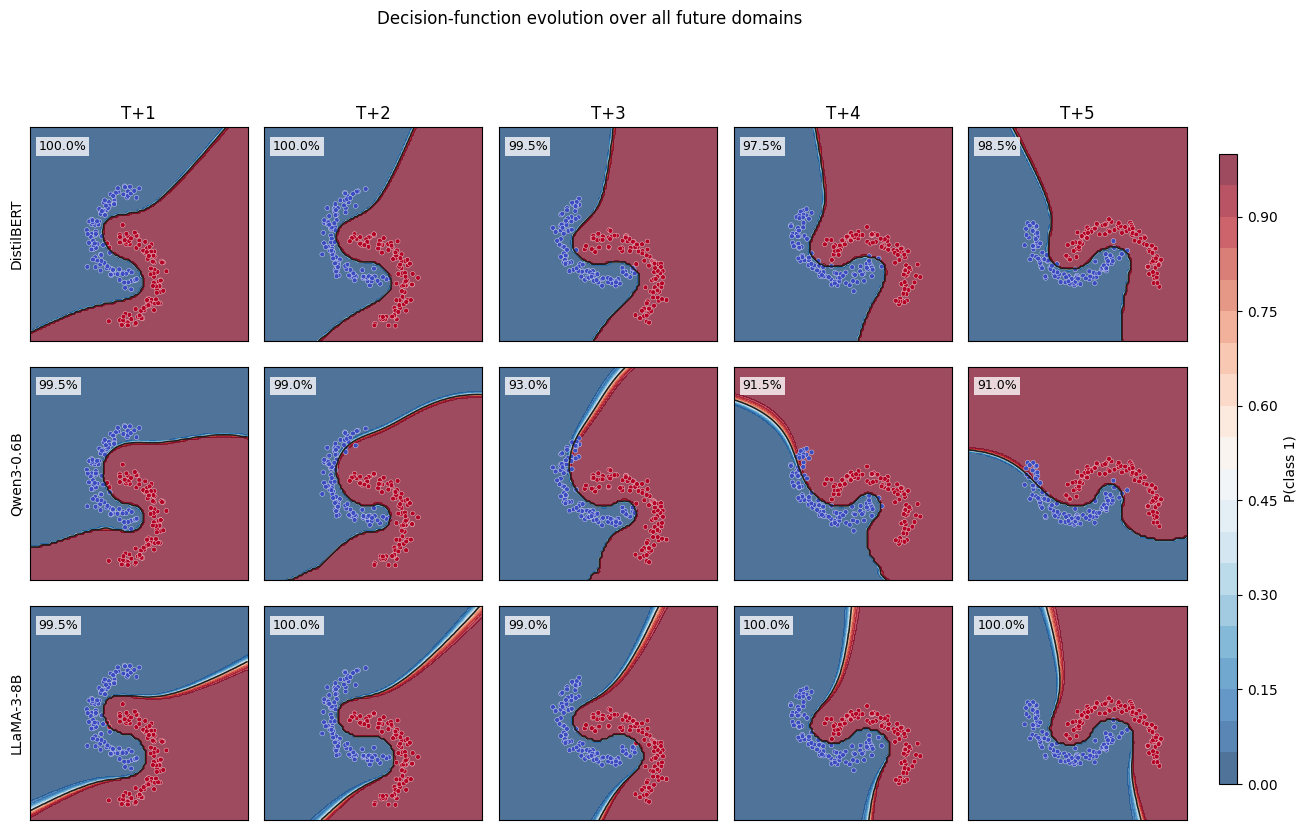

In [7]:
figure, axes = plt.subplots(len(BACKBONES), N_TEST, figsize=(15, 3.0 * len(BACKBONES)), squeeze=False)
levels = np.linspace(0, 1, 21)
for row, backbone in enumerate(BACKBONES):
    for column, (t, x, y) in enumerate(future):
        axis = axes[row, column]
        probability = surfaces[backbone][t]
        image = axis.contourf(grid_x, grid_y, probability, levels=levels, cmap="RdBu_r", vmin=0, vmax=1, alpha=0.72)
        axis.contour(grid_x, grid_y, probability, levels=[0.5], colors="#202020", linewidths=1.2)
        axis.scatter(x[:, 0], x[:, 1], c=y, cmap="coolwarm", vmin=0, vmax=1, s=12, edgecolors="white", linewidths=0.25)
        accuracy = 100 * results[backbone]["future_accuracy"][str(t)]
        if row == 0:
            axis.set_title(f"T+{column + 1}")
        axis.text(0.04, 0.94, f"{accuracy:.1f}%", transform=axis.transAxes, va="top", fontsize=9,
                  bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 2})
        if column == 0:
            axis.set_ylabel(CFG[backbone]["name"])
        axis.set_xlim(x_limits)
        axis.set_ylim(y_limits)
        axis.set_aspect("equal")
        axis.set_xticks([])
        axis.set_yticks([])
figure.subplots_adjust(wspace=0.05, hspace=0.12, right=0.90)
colorbar_axis = figure.add_axes([0.92, 0.15, 0.012, 0.70])
colorbar = figure.colorbar(image, cax=colorbar_axis)
colorbar.set_label("P(class 1)")
figure.suptitle("Decision-function evolution over all future domains", y=1.01)
plt.show()

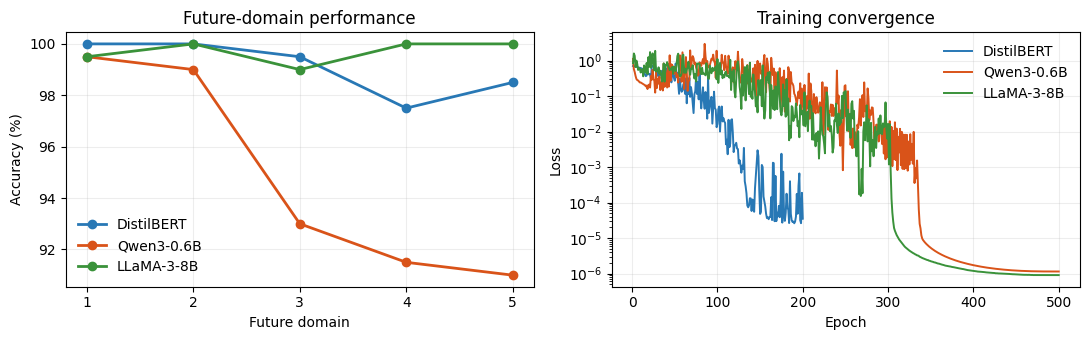

In [8]:
colors = ["#2878B5", "#D95319", "#3A923A"]
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for color, backbone in zip(colors, BACKBONES):
    record = results[backbone]
    steps = np.arange(1, N_TEST + 1)
    values = [100 * record["future_accuracy"][str(N_TRAIN + index)] for index in range(N_TEST)]
    axes[0].plot(steps, values, marker="o", linewidth=2, label=record["backbone"], color=color)
    epochs = np.arange(1, len(record["loss_history"]) + 1)
    axes[1].plot(epochs, record["loss_history"], linewidth=1.4, label=record["backbone"], color=color)
axes[0].set(title="Future-domain performance", xlabel="Future domain", ylabel="Accuracy (%)", xticks=steps)
axes[1].set(title="Training convergence", xlabel="Epoch", ylabel="Loss", yscale="log")
for axis in axes:
    axis.grid(alpha=0.22)
    axis.legend(frameon=False)
figure.tight_layout()
plt.show()